In [1]:
"""Part A data: EuroSAT RGB satellite tiles (64 x 64, 10 land-cover classes)."""

import numpy as np
import torch
from datasets import load_dataset

EUROSAT_REPO = "blanchon/EuroSAT_RGB"

CLASS_NAMES = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
]

PATCH = 8  # 64 / 8 = 8 x 8 = 64 patches per image


def load_eurosat_split(split):
    """split in {'train', 'validation', 'test'}.
    Returns images (N, 3, 64, 64) float32 in [0, 1] and labels (N,) int64.
    """
    ds = load_dataset(EUROSAT_REPO, split=split)

    imgs = np.stack([
        np.asarray(im.convert("RGB"), dtype=np.uint8)
        for im in ds["image"]
    ])

    images = torch.from_numpy(imgs).permute(0, 3, 1, 2).float() / 255.0
    labels = torch.tensor(ds["label"], dtype=torch.long)

    return images, labels


def few_label_indices(labels, per_class=16, seed=42):
    """Indices of a fixed labelled subset: per_class images of each class.
    Every group gets the same 160 images.
    """
    rng = np.random.default_rng(seed)
    idx = []

    for c in range(len(CLASS_NAMES)):
        members = np.flatnonzero(labels.numpy() == c)
        idx.extend(
            rng.choice(members, size=per_class, replace=False).tolist()
        )

    return torch.tensor(sorted(idx))


def patchify(images, p=PATCH):
    """(N, C, H, W) -> (N, L, p*p*C) with L = (H/p)*(W/p),
    patches in row-major order.
    """
    N, C, H, W = images.shape

    x = images.reshape(N, C, H // p, p, W // p, p)
    x = x.permute(0, 2, 4, 3, 5, 1)

    return x.reshape(N, (H // p) * (W // p), p * p * C)


def unpatchify(patches, p=PATCH, C=3):
    """Inverse of patchify: (N, L, p*p*C) -> (N, C, H, W)."""
    N, L, _ = patches.shape

    h = w = int(L ** 0.5)
    x = patches.reshape(N, h, w, p, p, C).permute(0, 5, 1, 3, 2, 4)

    return x.reshape(N, C, h * p, w * p)

In [2]:
import torch
from torch.utils.data import DataLoader
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# Load EuroSAT data
x_train, y_train = load_eurosat_split("train")
x_test, y_test = load_eurosat_split("test")

# Select 16 labelled images from each class
few_indices = few_label_indices(y_train)

# Convert images into patches
train_patches = patchify(x_train)
test_patches = patchify(x_test)

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Few labelled images:", len(few_indices))
print("Training patches:", train_patches.shape)
print("Testing patches:", test_patches.shape)

# DataLoader for MAE pretraining
train_loader = DataLoader(
    train_patches,
    batch_size=256,
    shuffle=True
)


Using device: cuda


README.md:   0%|          | 0.00/3.38k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  105MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 34.8MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/16200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5400 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5400 [00:00<?, ? examples/s]

Training images: torch.Size([16200, 3, 64, 64])
Testing images: torch.Size([5400, 3, 64, 64])
Few labelled images: 160
Training patches: torch.Size([16200, 64, 192])
Testing patches: torch.Size([5400, 64, 192])


In [3]:
import torch
import torch.nn as nn
def random_masking(x, keep=16):
    batch_size, num_patches, dim = x.shape

    noise = torch.rand(batch_size, num_patches, device=x.device)

    ids_shuffle = torch.argsort(noise, dim=1)
    ids_restore = torch.argsort(ids_shuffle, dim=1)

    ids_keep = ids_shuffle[:, :keep]

    visible = torch.gather(
        x,
        1,
        ids_keep.unsqueeze(-1).expand(-1, -1, dim)
    )

    mask = torch.ones(
        batch_size,
        num_patches,
        device=x.device
    )

    mask[:, :keep] = 0
    mask = torch.gather(mask, 1, ids_restore)

    return visible, mask, ids_restore


class MAEEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.patch_embed = nn.Linear(192, 192)

        self.pos_embed = nn.Parameter(
            torch.randn(1, 64, 192) * 0.02
        )

        layer = nn.TransformerEncoderLayer(
            d_model=192,
            nhead=3,
            dim_feedforward=768,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=6
        )

        self.norm = nn.LayerNorm(192)

    def forward(self, patches, mask_on=True):
        x = self.patch_embed(patches)
        x = x + self.pos_embed
        mask = None
        ids_restore = None
        if mask_on:
            x, mask, ids_restore = random_masking(x)
        x = self.transformer(x)
        x = self.norm(x)
        return x, mask, ids_restore

class MAEDecoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.projection = nn.Linear(192, 128)

        self.mask_token = nn.Parameter(
            torch.randn(1, 1, 128) * 0.02
        )

        self.pos_embed = nn.Parameter(
            torch.randn(1, 64, 128) * 0.02
        )

        layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=4,
            dim_feedforward=512,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        self.output = nn.Linear(128, 192)

    def forward(self, enc_tokens, ids_restore):
        x = self.projection(enc_tokens)
        batch_size = x.shape[0]
        mask_tokens = self.mask_token.expand(
            batch_size, 48, 128
        )
        x = torch.cat([x, mask_tokens], dim=1)
        x = torch.gather(
            x,
            1,
            ids_restore.unsqueeze(-1).expand(-1, -1, 128)
        )
        x = x + self.pos_embed
        x = self.transformer(x)
        return self.output(x)

class MAE(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = MAEEncoder()
        self.decoder = MAEDecoder()

    def forward(self, patches):
        enc_tokens, mask, ids_restore = self.encoder(
            patches,
            mask_on=True
        )
        predictions = self.decoder(enc_tokens, ids_restore)
        loss_per_patch = (
            (predictions - patches) ** 2
        ).mean(dim=-1)
        loss = (loss_per_patch * mask).sum() / mask.sum()
        return loss, predictions, mask


In [5]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [6]:
import json
import time
from pathlib import Path
import torch
from torch.optim import AdamW

EPOCHS = 100
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.05

results_dir = Path("/content/drive/MyDrive/MAE-VAE-DDPM-RAG/part_a_mae/results")
results_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = results_dir / "mae_final.pth"
loss_path = results_dir / "loss_history.json"

model = MAE().to(device)

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

start_epoch = 0
loss_history = []

if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    start_epoch = checkpoint["epoch"]
    if loss_path.exists():
        with open(loss_path, "r") as file:
            loss_history = json.load(file)

    print("Resuming from epoch:", start_epoch + 1)

else:
    print("Starting training from epoch 1")
parameter_count = sum(p.numel() for p in model.parameters())
print("Total parameters:", parameter_count)
start_time = time.time()

for epoch in range(start_epoch, EPOCHS):
    model.train()
    total_loss = 0
    total_images = 0

    for patches in train_loader:
        patches = patches.to(device)
        optimizer.zero_grad()
        loss, predictions, mask = model(patches)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * patches.size(0)
        total_images += patches.size(0)
    epoch_loss = total_loss / total_images
    loss_history.append(epoch_loss)

    print(f"Epoch [{epoch + 1}/{EPOCHS}] Loss: {epoch_loss:.4f}")

    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "loss": epoch_loss
    }

    torch.save(checkpoint, checkpoint_path)

    if (epoch + 1) % 10 == 0:
        torch.save(
            checkpoint,
            results_dir / f"mae_epoch_{epoch + 1}.pth"
        )

    with open(loss_path, "w") as file:
        json.dump(loss_history, file, indent=4)

training_time = time.time() - start_time

with open(results_dir / "training_info.json", "w") as file:
    json.dump(
        {
            "epochs": len(loss_history),
            "parameters": parameter_count,
            "training_time_seconds": training_time,
            "final_loss": loss_history[-1]
        },
        file,
        indent=4
    )

print("Training completed.")
print("Total epochs:", len(loss_history))
print("Training time:", round(training_time / 60, 2), "minutes")
print("Final loss:", loss_history[-1])


/tmp/ipykernel_459/995918546.py:48: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.transformer = nn.TransformerEncoder(


Starting training from epoch 1
Total parameters: 3173248
Epoch [1/100] Loss: 0.0578
Epoch [2/100] Loss: 0.0263
Epoch [3/100] Loss: 0.0159
Epoch [4/100] Loss: 0.0136
Epoch [5/100] Loss: 0.0120
Epoch [6/100] Loss: 0.0110
Epoch [7/100] Loss: 0.0102
Epoch [8/100] Loss: 0.0098
Epoch [9/100] Loss: 0.0094
Epoch [10/100] Loss: 0.0091
Epoch [11/100] Loss: 0.0091
Epoch [12/100] Loss: 0.0088
Epoch [13/100] Loss: 0.0087
Epoch [14/100] Loss: 0.0087
Epoch [15/100] Loss: 0.0087
Epoch [16/100] Loss: 0.0085
Epoch [17/100] Loss: 0.0084
Epoch [18/100] Loss: 0.0085
Epoch [19/100] Loss: 0.0084
Epoch [20/100] Loss: 0.0082
Epoch [21/100] Loss: 0.0081
Epoch [22/100] Loss: 0.0080
Epoch [23/100] Loss: 0.0079
Epoch [24/100] Loss: 0.0079
Epoch [25/100] Loss: 0.0080
Epoch [26/100] Loss: 0.0079
Epoch [27/100] Loss: 0.0078
Epoch [28/100] Loss: 0.0078
Epoch [29/100] Loss: 0.0078
Epoch [30/100] Loss: 0.0078
Epoch [31/100] Loss: 0.0077
Epoch [32/100] Loss: 0.0077
Epoch [33/100] Loss: 0.0077
Epoch [34/100] Loss: 0.0077


In [10]:
import torch
#Step 1: masking
x = torch.randn(8, 64, 192)
visible, mask, ids_restore = random_masking(x)

assert mask.sum(dim=1).eq(48).all(), "each image should have exactly 48 masked patches"
print("Masking test passed: masked per image =", mask.sum(dim=1).tolist())
print("visible:", tuple(visible.shape), "| mask:", tuple(mask.shape), "| ids_restore:", tuple(ids_restore.shape))

# new random choice on every call and for every image
_, mask2, _ = random_masking(x)
print("Different mask on a second call :", not torch.equal(mask, mask2))
print("Different masks inside one batch:", not torch.equal(mask[0], mask[1]))

# ids_restore puts visible tokens back in the right slots
tokens = torch.arange(64).float().view(1, 64, 1).expand(2, 64, 1)
vis, m, ir = random_masking(tokens)
full = torch.cat([vis, torch.zeros(2, 48, 1)], dim=1)
back = torch.gather(full, 1, ir.unsqueeze(-1))
kept = (m == 0)
assert torch.equal(back[kept], tokens[kept]), "ids_restore did not restore the order"
print("ids_restore test passed: visible tokens are back in their original slots")

#Step 2: encoder shapes (fresh model)
enc = MAEEncoder()
inp = torch.randn(8, 64, 192)
out_m, _, _ = enc(inp, mask_on=True)
out_f, _, _ = enc(inp, mask_on=False)
print("Encoder masked   :", tuple(out_m.shape))    # (8, 16, 192)
print("Encoder unmasked :", tuple(out_f.shape))    # (8, 64, 192)
assert out_m.shape == (8, 16, 192) and out_f.shape == (8, 64, 192)

#Step 3: decoder shape
dec = MAEDecoder()
e, m, ir = enc(inp, mask_on=True)
dec_out = dec(e, ir)
print("Decoder output   :", tuple(dec_out.shape))  # (8, 64, 192)
assert dec_out.shape == (8, 64, 192)

#Step 4: full MAE (fresh model)
loss, pred, m = MAE()(inp)
print("MAE loss:", round(loss.item(), 4), "| pred:", tuple(pred.shape), "| mask:", tuple(m.shape))

#Same checks on your TRAINED model
from pathlib import Path
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

results_dir = Path("/content/drive/MyDrive/MAE-VAE-DDPM-RAG/part_a_mae/results")
checkpoint_path = results_dir / "mae_final.pth"

model = MAE().to(device)
ckpt = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print("Loaded weights from epoch:", ckpt["epoch"])   # should print 100
print("Final training loss      :", round(ckpt["loss"], 5))
print("Parameters               :", f"{sum(p.numel() for p in model.parameters()):,}")

model.eval()
dev = next(model.parameters()).device
with torch.no_grad():
    t_in = test_patches[:8].to(dev)
    t_loss, t_pred, t_mask = model(t_in)
    t_enc_m, _, _ = model.encoder(t_in, mask_on=True)
    t_enc_f, _, _ = model.encoder(t_in, mask_on=False)

assert t_mask.sum(dim=1).eq(48).all()
print("\nTrained model:")
print("  masked per image :", t_mask.sum(dim=1).tolist())
print("  encoder masked   :", tuple(t_enc_m.shape))
print("  encoder unmasked :", tuple(t_enc_f.shape))
print("  prediction       :", tuple(t_pred.shape))
print("  loss on 8 test imgs:", round(t_loss.item(), 4))
print("\nAll checks passed.")

Masking test passed: masked per image = [48.0, 48.0, 48.0, 48.0, 48.0, 48.0, 48.0, 48.0]
visible: (8, 16, 192) | mask: (8, 64) | ids_restore: (8, 64)
Different mask on a second call : True
Different masks inside one batch: True
ids_restore test passed: visible tokens are back in their original slots
Encoder masked   : (8, 16, 192)
Encoder unmasked : (8, 64, 192)
Decoder output   : (8, 64, 192)


/tmp/ipykernel_459/995918546.py:48: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.transformer = nn.TransformerEncoder(


MAE loss: 1.36 | pred: (8, 64, 192) | mask: (8, 64)
Loaded weights from epoch: 100
Final training loss      : 0.0063
Parameters               : 3,173,248

Trained model:
  masked per image : [48.0, 48.0, 48.0, 48.0, 48.0, 48.0, 48.0, 48.0]
  encoder masked   : (8, 16, 192)
  encoder unmasked : (8, 64, 192)
  prediction       : (8, 64, 192)
  loss on 8 test imgs: 0.0087

All checks passed.


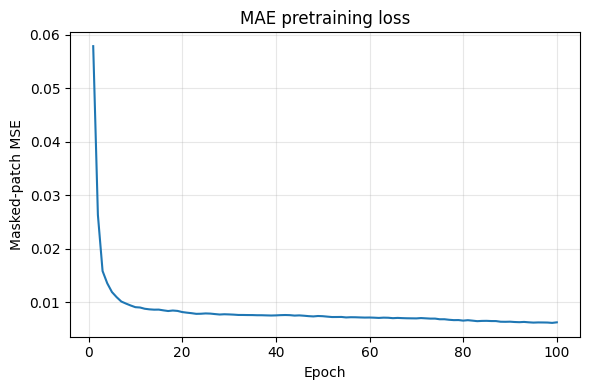

In [13]:
import matplotlib.pyplot as plt
loss_history = json.load(open(loss_path))

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Masked-patch MSE")
plt.title("MAE pretraining loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(results_dir / "loss_curve.png", dpi=150)
plt.show()

Loaded weights from epoch 100


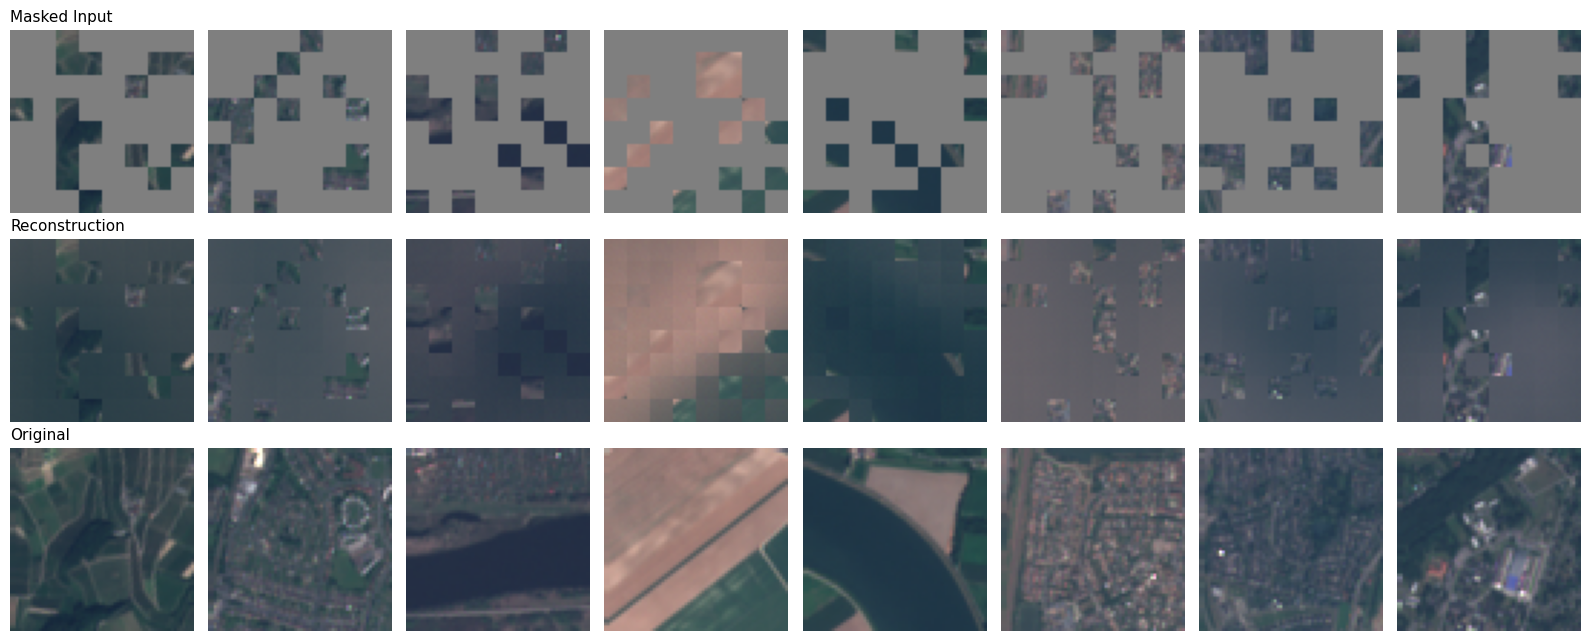

In [14]:
ckpt = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(ckpt["model_state_dict"])
print("Loaded weights from epoch", ckpt["epoch"])

model.eval()
torch.manual_seed(0)

idx = torch.randperm(len(test_patches))[:8]
original = test_patches[idx].to(device)

with torch.no_grad():
    _, pred, mask = model(original)

pred = pred.clamp(0, 1)

masked_input = original.clone()
masked_input[mask.bool()] = 0.5

reconstruction = torch.where(mask.bool().unsqueeze(-1), pred, original)

def to_imgs(patches):
    return unpatchify(patches).permute(0, 2, 3, 1).cpu().numpy()

rows = [
    to_imgs(masked_input),
    to_imgs(reconstruction),
    to_imgs(original)
]

titles = ["Masked Input", "Reconstruction", "Original"]

fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))

for i in range(3):
    for j in range(8):
        axes[i, j].imshow(rows[i][j].clip(0, 1))
        axes[i, j].axis("off")

    axes[i, 0].set_title(titles[i], loc="left", fontsize=11)

plt.tight_layout()
plt.savefig(results_dir / "reconstructions.png", dpi=150)
plt.show()

In [15]:
@torch.no_grad()
def extract_features(encoder, patches, bs=512):
    encoder.eval()
    feats = []

    for i in range(0, len(patches), bs):
        out, _, _ = encoder(patches[i:i + bs].to(device), mask_on=False)
        feats.append(out.mean(dim=1).cpu())

    return torch.cat(feats)


train_feats = extract_features(model.encoder, train_patches[few_indices])
train_labels = y_train[few_indices]

test_feats = extract_features(model.encoder, test_patches)

print("Few-label features:", tuple(train_feats.shape))
print("Test features:", tuple(test_feats.shape))
print("Labels per class:", torch.bincount(train_labels).tolist())

train_feats = train_feats.to(device)
train_labels = train_labels.to(device)
test_feats = test_feats.to(device)
y_test_dev = y_test.to(device)

torch.manual_seed(0)

clf = nn.Linear(192, 10).to(device)
clf_opt = AdamW(clf.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(200):
    clf.train()
    clf_opt.zero_grad()

    loss = criterion(clf(train_feats), train_labels)
    loss.backward()
    clf_opt.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}/200 - Loss: {loss.item():.4f}")

clf.eval()

with torch.no_grad():
    train_pred = clf(train_feats).argmax(dim=1)
    test_pred = clf(test_feats).argmax(dim=1)

    train_acc = (train_pred == train_labels).float().mean().item()
    test_acc = (test_pred == y_test_dev).float().mean().item()

print(f"Train accuracy (160 images): {train_acc * 100:.2f}%")
print(f"Test accuracy (5400 images): {test_acc * 100:.2f}%")

Few-label features: (160, 192)
Test features: (5400, 192)
Labels per class: [16, 16, 16, 16, 16, 16, 16, 16, 16, 16]
Epoch 50/200 - Loss: 1.2910
Epoch 100/200 - Loss: 1.0661
Epoch 150/200 - Loss: 0.9464
Epoch 200/200 - Loss: 0.8622
Train accuracy (160 images): 71.25%
Test accuracy (5400 images): 52.17%


Row sums: [596, 608, 573, 496, 501, 396, 538, 554, 529, 609]


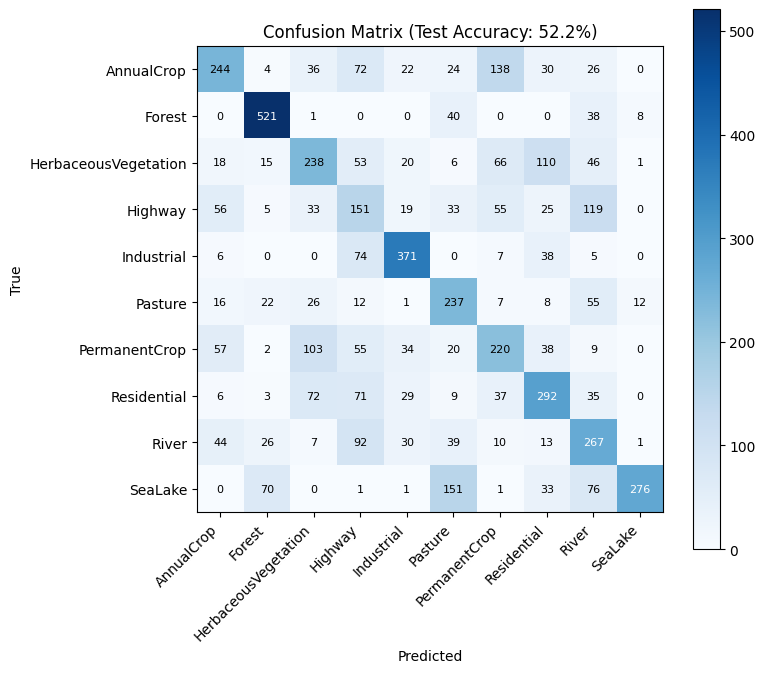

In [16]:
conf = torch.zeros(10, 10, dtype=torch.long)

for true, pred in zip(y_test.tolist(), test_pred.cpu().tolist()):
    conf[true, pred] += 1

print("Row sums:", conf.sum(dim=1).tolist())

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(conf.numpy(), cmap="Blues")

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticklabels(CLASS_NAMES)

ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Confusion Matrix (Test Accuracy: {test_acc * 100:.1f}%)")

thresh = conf.max().item() / 2

for i in range(10):
    for j in range(10):
        ax.text(
            j, i, int(conf[i, j]),
            ha="center",
            va="center",
            fontsize=8,
            color="white" if conf[i, j] > thresh else "black"
        )

plt.colorbar(im)
plt.tight_layout()
plt.savefig(results_dir / "confusion_matrix.png", dpi=150)
plt.show()

results = {
    "test_accuracy": test_acc,
    "train_accuracy_160": train_acc,
    "confusion_matrix": conf.tolist()
}

with open(results_dir / "classifier_results.json", "w") as f:
    json.dump(results, f, indent=4)

In [18]:
import json
from pathlib import Path

results_dir = Path("/content/drive/MyDrive/MAE-VAE-DDPM-RAG/part_a_mae/results")
info_path = results_dir / "training_info.json"

with open(info_path) as f:
    info = json.load(f)

print("Table 2 (Pretraining)")
print("Final loss    :", round(info["final_loss"], 5))
print("Parameters    :", f"{info['parameters']:,}")
print("Training time :", round(info["training_time_seconds"] / 60, 1), "min")
print("Epochs        :", info["epochs"])

Table 2 (Pretraining)
Final loss    : 0.0063
Parameters    : 3,173,248
Training time : 8.2 min
Epochs        : 100


In [19]:
!pip install -q huggingface_hub

In [20]:
import torch
from pathlib import Path

results_dir = Path("/content/drive/MyDrive/MAE-VAE-DDPM-RAG/part_a_mae/results")

ckpt = torch.load(results_dir / "mae_final.pth", map_location="cpu")
torch.save(ckpt["model_state_dict"], results_dir / "mae_weights.pth")
print("Saved weights from epoch", ckpt["epoch"])    # should say 100

Saved weights from epoch 100
